<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/mean_tension_overall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Average pendulum tension in the libration and rotation regimes ($0^{\circ}<\theta<360^{\circ}$)

<>:152: SyntaxWarning: invalid escape sequence '\c'
<>:152: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_855/1633976767.py:152: SyntaxWarning: invalid escape sequence '\c'
  ax1.plot(theta0, omega0, 'ko', markersize=8, label='Start ($t=0$, Peak $105.6^\circ$)')


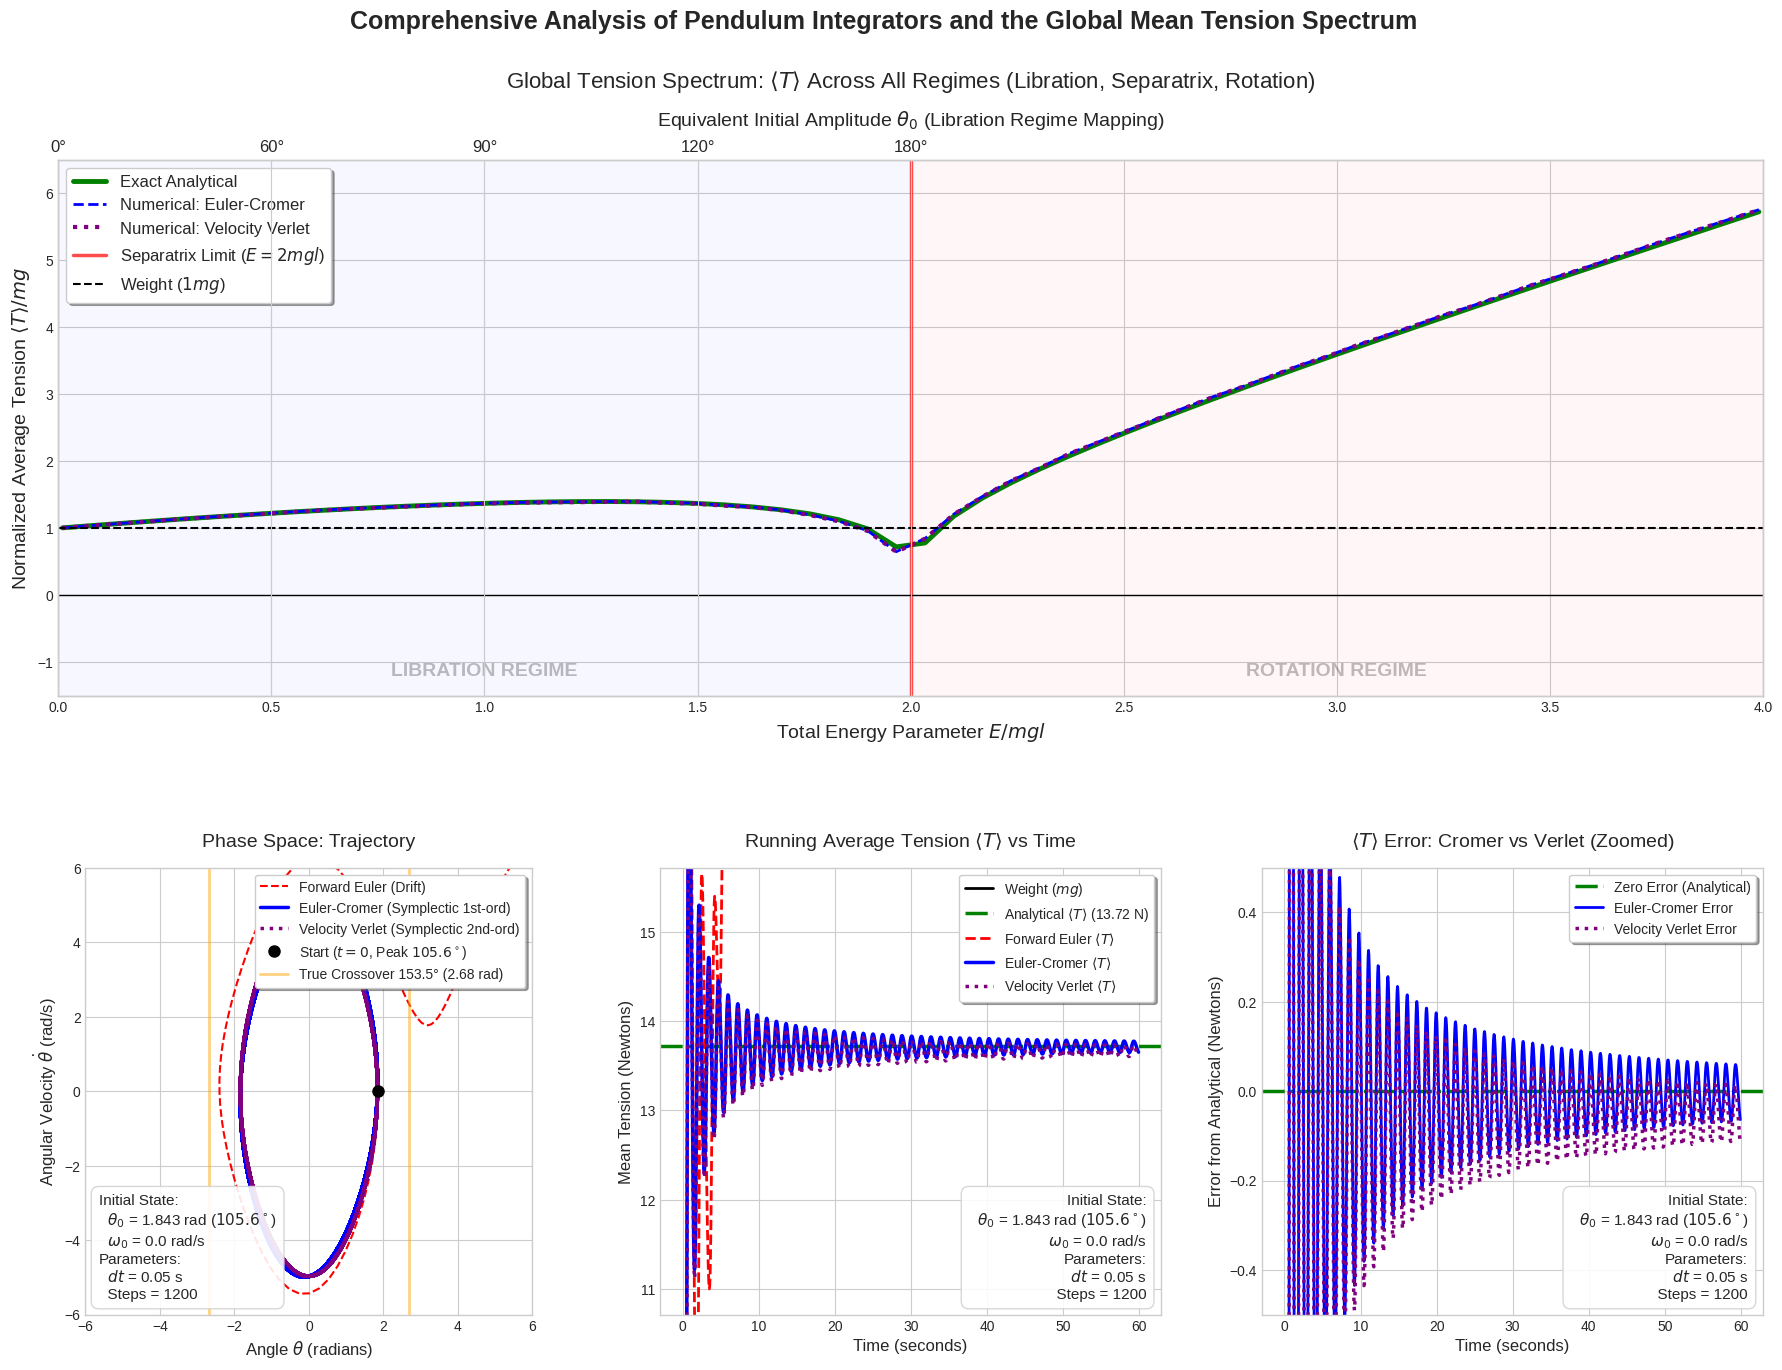

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.special import ellipk, ellipe

def simulate_pendulum(method='euler-cromer', dt=0.05, steps=400, theta0=1.0, omega0=0.0):
    """
    Simulates a nonlinear pendulum: d^2(theta)/dt^2 = -(g/L)*sin(theta)

    Args:
        method: 'forward-euler', 'euler-cromer', or 'velocity-verlet'
        dt: Time step size
        steps: Number of integration steps
        theta0: Initial angle (radians)
        omega0: Initial angular velocity (radians/s)
    """
    g = 9.81
    L = 1.0
    m = 1.0 # Assume a 1 kg mass for tension calculations

    t_vals = np.zeros(steps)
    theta_vals = np.zeros(steps)
    omega_vals = np.zeros(steps)

    theta_vals[0] = theta0
    omega_vals[0] = omega0
    t_vals[0] = 0.0

    for i in range(1, steps):
        theta_prev = theta_vals[i-1]
        omega_prev = omega_vals[i-1]
        t_vals[i] = t_vals[i-1] + dt

        if method == 'velocity-verlet':
            # Velocity Verlet (2nd order symplectic)
            alpha_current = -(g / L) * np.sin(theta_prev)
            theta_vals[i] = theta_prev + omega_prev * dt + 0.5 * alpha_current * dt**2

            alpha_new = -(g / L) * np.sin(theta_vals[i])
            omega_vals[i] = omega_prev + 0.5 * (alpha_current + alpha_new) * dt

        else:
            # Calculate acceleration for 1st order methods
            alpha = -(g / L) * np.sin(theta_prev)

            if method == 'forward-euler':
                # Explicit: Update position using OLD velocity
                theta_vals[i] = theta_prev + omega_prev * dt
                omega_vals[i] = omega_prev + alpha * dt

            elif method == 'euler-cromer':
                # Symplectic/Semi-implicit: Update position using NEW velocity
                omega_vals[i] = omega_prev + alpha * dt
                theta_vals[i] = theta_prev + omega_vals[i] * dt

    # Calculate Instantaneous Tension: T = mg*cos(theta) + m*L*omega^2
    tension_vals = m * g * np.cos(theta_vals) + m * L * omega_vals**2

    # Calculate Running Mean Tension
    mean_tension_vals = np.cumsum(tension_vals) / np.arange(1, steps + 1)

    return t_vals, theta_vals, omega_vals, tension_vals, mean_tension_vals

# --- Simulation Parameters for Top Row ---
dt = 0.05
steps = 1200
# Corrected initial angle to the TRUE Maximum Excess peak (105.6 degrees = 1.843 rad)
theta0 = 1.843
omega0 = 0.0

m = 1.0
g = 9.81

# Run simulations for Top Row
t_FE, theta_FE, omega_FE, T_FE, mean_T_FE = simulate_pendulum('forward-euler', dt, steps, theta0, omega0)
t_EC, theta_EC, omega_EC, T_EC, mean_T_EC = simulate_pendulum('euler-cromer', dt, steps, theta0, omega0)
t_VV, theta_VV, omega_VV, T_VV, mean_T_VV = simulate_pendulum('velocity-verlet', dt, steps, theta0, omega0)

# Exact Analytical Mean Tension for Top Row
k_sq = np.sin(theta0 / 2)**2
K_val = ellipk(k_sq)
E_val = ellipe(k_sq)
analytical_mean_T = m * g * ((6 * E_val / K_val) + 4 * k_sq - 5)


# --- Generate Data for Global Spectrum Plot (Bottom Row) ---
# We parameterize by Energy E/mgl to smoothly cross the separatrix into rotation.
energy_levels = np.linspace(0.01, 3.99, 60)
exact_T_all = []
ec_T_all = []
vv_T_all = []

for e in energy_levels:
    # Set initial conditions at the bottom (theta=0) with velocity corresponding to Energy E
    w0 = np.sqrt(2 * g / 1.0 * e)

    # 1. Analytical Exact (Normalized by removing the m*g factor)
    if e < 2.0:
        # Libration
        k2 = e / 2.0
        K = ellipk(k2)
        E_val = ellipe(k2)
        exact_val = ((6 * E_val / K) + 4 * k2 - 5)
    elif np.isclose(e, 2.0):
        # Separatrix limit
        exact_val = -1.0
    else:
        # Rotation
        k_rot_sq = 2.0 / e
        K = ellipk(k_rot_sq)
        E_val = ellipe(k_rot_sq)
        exact_val = ((6 * E_val / (k_rot_sq * K)) - (2 / k_rot_sq) + 1)

    exact_T_all.append(exact_val)

    # 2. Numerical Euler-Cromer (simulate and take final running average, normalized)
    _, _, _, _, mean_EC = simulate_pendulum('euler-cromer', dt=0.05, steps=1500, theta0=0.0, omega0=w0)
    ec_T_all.append(mean_EC[-1] / (m * g))

    # 3. Numerical Velocity Verlet (normalized)
    _, _, _, _, mean_VV = simulate_pendulum('velocity-verlet', dt=0.05, steps=1500, theta0=0.0, omega0=w0)
    vv_T_all.append(mean_VV[-1] / (m * g))


# --- Plotting ---
plt.style.use('seaborn-v0_8-whitegrid')
fig = plt.figure(figsize=(22, 15))
gs = gridspec.GridSpec(2, 3, height_ratios=[1.2, 1], hspace=0.35)

# Swap the subplot placements
ax4 = fig.add_subplot(gs[0, :]) # 4th plot now spanning the entire top row
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[1, 1])
ax3 = fig.add_subplot(gs[1, 2])

# Common text box properties for parameters
param_str = (
    f"Initial State:\n"
    f"  $\\theta_0$ = {theta0:.3f} rad ($105.6^\\circ$)\n"
    f"  $\\omega_0$ = {omega0:.1f} rad/s\n"
    f"Parameters:\n"
    f"  $dt$ = {dt} s\n"
    f"  Steps = {steps}"
)
props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='lightgray')

# --- Subplot 1: Phase Space ---
ax1.plot(theta_FE, omega_FE, '--', color='red', linewidth=1.5, label='Forward Euler (Drift)')
ax1.plot(theta_EC, omega_EC, '-', color='blue', linewidth=2.5, label='Euler-Cromer (Symplectic 1st-ord)')
ax1.plot(theta_VV, omega_VV, ':', color='purple', linewidth=2.5, label='Velocity Verlet (Symplectic 2nd-ord)')

ax1.plot(theta0, omega0, 'ko', markersize=8, label='Start ($t=0$, Peak $105.6^\circ$)')

true_crossover_rad = 153.5 * np.pi / 180
ax1.axvline(x=true_crossover_rad, color='orange', linestyle='-', alpha=0.5, linewidth=2,
            label=f'True Crossover 153.5° ({true_crossover_rad:.2f} rad)')
ax1.axvline(x=-true_crossover_rad, color='orange', linestyle='-', alpha=0.5, linewidth=2)

ax1.set_title('Phase Space: Trajectory', fontsize=14, pad=15)
ax1.set_xlabel('Angle $\\theta$ (radians)', fontsize=12)
ax1.set_ylabel('Angular Velocity $\\dot{\\theta}$ (rad/s)', fontsize=12)
ax1.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
ax1.set_xlim(-6, 6)
ax1.set_ylim(-6, 6)
ax1.set_aspect('equal', adjustable='box')

# Add parameters text box
ax1.text(0.03, 0.03, param_str, transform=ax1.transAxes, fontsize=11,
         verticalalignment='bottom', bbox=props)

# --- Subplot 2: Running Mean Tension ---
ax2.axhline(y=m*g, color='black', linestyle='-', linewidth=2, label='Weight ($mg$)')
ax2.axhline(y=analytical_mean_T, color='green', linestyle='-.', linewidth=2.5,
            label=f'Analytical $\\langle T \\rangle$ ({analytical_mean_T:.2f} N)')

ax2.plot(t_FE, mean_T_FE, '--', color='red', linewidth=2, label='Forward Euler $\\langle T \\rangle$')
ax2.plot(t_EC, mean_T_EC, '-', color='blue', linewidth=2.5, label='Euler-Cromer $\\langle T \\rangle$')
ax2.plot(t_VV, mean_T_VV, ':', color='purple', linewidth=2.5, label='Velocity Verlet $\\langle T \\rangle$')

ax2.set_title('Running Average Tension $\\langle T \\rangle$ vs Time', fontsize=14, pad=15)
ax2.set_xlabel('Time (seconds)', fontsize=12)
ax2.set_ylabel('Mean Tension (Newtons)', fontsize=12)
ax2.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
ax2.set_ylim(analytical_mean_T - 3.0, analytical_mean_T + 2.0)

# Add parameters text box
ax2.text(0.97, 0.03, param_str, transform=ax2.transAxes, fontsize=11,
         verticalalignment='bottom', horizontalalignment='right', bbox=props)

# --- Subplot 3: Integration Error Zoom ---
ax3.axhline(y=0, color='green', linestyle='-.', linewidth=2.5, label='Zero Error (Analytical)')

error_EC = mean_T_EC - analytical_mean_T
error_VV = mean_T_VV - analytical_mean_T

ax3.plot(t_EC, error_EC, '-', color='blue', linewidth=2, label='Euler-Cromer Error')
ax3.plot(t_VV, error_VV, ':', color='purple', linewidth=2.5, label='Velocity Verlet Error')

ax3.set_title('$\\langle T \\rangle$ Error: Cromer vs Verlet (Zoomed)', fontsize=14, pad=15)
ax3.set_xlabel('Time (seconds)', fontsize=12)
ax3.set_ylabel('Error from Analytical (Newtons)', fontsize=12)
ax3.legend(loc='upper right', frameon=True, shadow=True, fontsize=10)
ax3.set_ylim(-0.5, 0.5)

# Add parameters text box
ax3.text(0.97, 0.03, param_str, transform=ax3.transAxes, fontsize=11,
         verticalalignment='bottom', horizontalalignment='right', bbox=props)


# --- Subplot 4: Global Spectrum (All Regimes) ---
# Main plotting against Energy
ax4.plot(energy_levels, exact_T_all, '-', color='green', linewidth=3.5, label='Exact Analytical')
ax4.plot(energy_levels, ec_T_all, '--', color='blue', linewidth=2, label='Numerical: Euler-Cromer')
ax4.plot(energy_levels, vv_T_all, ':', color='purple', linewidth=3, label='Numerical: Velocity Verlet')

ax4.axvline(x=2.0, color='red', linestyle='-', linewidth=2.5, alpha=0.7, label='Separatrix Limit ($E=2mgl$)')
ax4.axhline(y=1.0, color='black', linestyle='--', linewidth=1.5, label='Weight ($1 mg$)')
ax4.axhline(y=0.0, color='black', linestyle='-', linewidth=1)

# Highlight Regimes
ax4.axvspan(0, 2.0, color='blue', alpha=0.03)
ax4.text(1.0, -1.2, "LIBRATION REGIME", ha='center', fontsize=14, fontweight='bold', alpha=0.3)
ax4.axvspan(2.0, 4.0, color='red', alpha=0.03)
ax4.text(3.0, -1.2, "ROTATION REGIME", ha='center', fontsize=14, fontweight='bold', alpha=0.3)

ax4.set_title('Global Tension Spectrum: $\\langle T \\rangle$ Across All Regimes (Libration, Separatrix, Rotation)', fontsize=16, pad=15)
ax4.set_xlabel('Total Energy Parameter $E / mgl$', fontsize=14)
ax4.set_ylabel('Normalized Average Tension $\\langle T \\rangle / mg$', fontsize=14)
ax4.set_xlim(0, 4)
# Expanded limits so the rotation regime curve remains fully visible
ax4.set_ylim(-1.5, 6.5)
ax4.legend(loc='upper left', frameon=True, shadow=True, fontsize=12)

# Create a secondary top X-axis to map Energy back to Initial Amplitude Theta
ax4_top = ax4.twiny()
ax4_top.set_xlim(ax4.get_xlim())

# Calculate custom tick locations for the corresponding angles in Libration
tick_energies = [0, 0.5, 1.0, 1.5, 2.0]
tick_angles = [np.degrees(np.arccos(1 - e)) for e in tick_energies]

ax4_top.set_xticks(tick_energies)
ax4_top.set_xticklabels([f"{angle:.0f}°" for angle in tick_angles], fontsize=12)
ax4_top.set_xlabel(r"Equivalent Initial Amplitude $\theta_0$ (Libration Regime Mapping)", fontsize=14, labelpad=10)


plt.suptitle('Comprehensive Analysis of Pendulum Integrators and the Global Mean Tension Spectrum', fontsize=18, y=0.98, fontweight='bold')
plt.show()